In [1]:
# ============================================================
# STEP 1 — LOAD ANNOTATED DATA AND EXTRACT THE T-CELL POPULATION
# ============================================================
#
# Goal:
# Our previous analysis identified an MS-associated transcriptional
# signature in the broad "Naive/memory-like T" population.
#
# We now want to investigate whether this broad population contains
# more specific T-cell states/subtypes and determine which of them
# may contribute to the translation/mitochondrial signal.
#
# IMPORTANT:
# We are NOT assuming beforehand that these cells are CD4, Treg,
# memory, etc. We will examine the data first and assign labels only
# when supported by marker expression.
# ============================================================

import scanpy as sc
import pandas as pd
import numpy as np

# Load the annotated single-cell dataset
adata = sc.read_h5ad("../data/adata_annotated.h5ad")

print("Full dataset:")
print(adata)
print()

# Extract only the broad Naive/memory-like T-cell population
tcell = adata[
    adata.obs["cell_type"] == "Naive/memory-like T"
].copy()

print("Naive/memory-like T-cell subset:")
print(tcell)

print("\nNumber of cells:")
print(tcell.n_obs)

print("\nAvailable metadata columns:")
print(tcell.obs.columns.tolist())

Full dataset:
AnnData object with n_obs × n_vars = 168077 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_0_5', 'cell_type'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'cell_type_colors', 'compartment_colors', 'dendrogram_leiden_0_5', 'hvg', 'leiden_0_5', 'leiden_0_5_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

Naive/memory-like T-cell subset:
AnnData object with n_obs × n_vars = 80895 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_0_5', 'cell_

In [2]:
# ============================================================
# STEP 2 — INSPECT THE EXPRESSION MATRIX
# ============================================================
#
# Before recalculating highly variable genes and PCA specifically
# within the T-cell population, we need to confirm what values are
# stored in tcell.X.
#
# For clustering/subclustering we WANT normalized/log-transformed
# expression values.
#
# Raw integer UMI counts will still be used later if we perform
# donor-level differential expression within individual T-cell
# subtypes.
# ============================================================

import scipy.sparse as sp

print("Matrix type:")
print(type(tcell.X))

# Extract the stored values efficiently
if sp.issparse(tcell.X):
    values = tcell.X.data
else:
    values = np.asarray(tcell.X).ravel()

print("\nExpression value summary:")
print("Minimum:", values.min())
print("Maximum:", values.max())
print("Mean:", values.mean())

# Check whether the non-zero values look like integers
print("\nFirst 20 stored non-zero values:")
print(values[:20])

print("\nAre all stored values integer-like?")
print(np.allclose(values, np.round(values)))

print("\nDoes this AnnData object contain a raw slot?")
print(tcell.raw is not None)

print("\nAvailable layers:")
print(list(tcell.layers.keys()))

Matrix type:
<class 'scipy.sparse._csr.csr_matrix'>

Expression value summary:
Minimum: 0.83056647
Maximum: 4.2566543
Mean: 2.1343176

First 20 stored non-zero values:
[2.1662402 2.1662402 2.1662402 2.4631543 3.0260744 2.1662402 2.1662402
 2.1662402 2.1662402 2.1662402 2.1662402 2.4631543 2.1662402 2.1662402
 3.296956  2.1662402 2.8822222 2.1662402 2.4631543 2.1662402]

Are all stored values integer-like?
False

Does this AnnData object contain a raw slot?
False

Available layers:
[]


In [4]:
# ============================================================
# STEP 3 — RECALCULATE HIGHLY VARIABLE GENES WITHIN T CELLS
# ============================================================
#
# We want to identify genes that vary specifically WITHIN our
# broad Naive/memory-like T-cell population.
#
# The expression matrix is already normalized and log-transformed,
# so we do NOT normalize or log-transform it again.
#
# We use flavor="seurat", which works with log-transformed data.
#
# NOTE:
# We originally tried flavor="cell_ranger", but it failed because
# many genes had identical/similar mean-expression values, producing
# duplicate expression-bin boundaries. This is a technical binning
# issue rather than evidence of a problem with the dataset.
# ============================================================

# Preserve the original whole-dataset HVG information
# (only create this column if it does not already exist)
if "highly_variable_whole_dataset" not in tcell.var.columns:
    tcell.var["highly_variable_whole_dataset"] = tcell.var["highly_variable"].copy()

# Recalculate HVGs specifically within the T-cell subset
sc.pp.highly_variable_genes(
    tcell,
    n_top_genes=3000,
    flavor="seurat"
)

print("Number of T-cell-specific HVGs:")
print(tcell.var["highly_variable"].sum())

print("\nFirst 20 T-cell-specific HVGs:")
print(
    tcell.var_names[tcell.var["highly_variable"]][:20].tolist()
)

Number of T-cell-specific HVGs:
3000

First 20 T-cell-specific HVGs:
['FAM87B', 'ISG15', 'LINC01342', 'TNFRSF4', 'MIB2', 'CFAP74', 'AL139246.4', 'PRDM16', 'CCDC27', 'TAS1R1', 'LINC01672', 'CAMTA1-DT', 'TNFRSF9', 'SLC2A5', 'LINC01647', 'C1orf167', 'TNFRSF1B', 'AC254633.1', 'HNRNPCL1', 'PDPN']


In [5]:
# ============================================================
# STEP 4 — T-CELL-SPECIFIC PCA
# ============================================================
#
# WHY?
# The PCA stored in the original AnnData object was calculated
# across the complete immune-cell dataset.
#
# That PCA mainly captures large differences such as:
#     T cells vs B cells vs monocytes vs NK cells
#
# We now want to capture more subtle variation WITHIN our broad
# Naive/memory-like T-cell population.
#
# Therefore we recalculate PCA using the 3,000 genes identified
# as highly variable specifically within these T cells.
#
# We calculate 50 principal components.
#
# IMPORTANT:
# We are not performing differential expression here.
# Individual cells can appropriately be used for this exploratory
# dimensionality-reduction/clustering step. Donor-level replication
# will become important again when we test MS-vs-Healthy differences.
# ============================================================

sc.tl.pca(
    tcell,
    n_comps=50,
    use_highly_variable=True,
    svd_solver="arpack"
)

print("PCA completed.")

print("\nPCA matrix shape:")
print(tcell.obsm["X_pca"].shape)

print("\nVariance explained by the first 10 PCs:")
print(tcell.uns["pca"]["variance_ratio"][:10])

print("\nCumulative variance explained by first 10 PCs:")
print(tcell.uns["pca"]["variance_ratio"][:10].sum())

/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


PCA completed.

PCA matrix shape:
(80895, 50)

Variance explained by the first 10 PCs:
[0.03140721 0.02273047 0.01494436 0.00993673 0.00941368 0.00780917
 0.00737432 0.00675855 0.00564857 0.00544844]

Cumulative variance explained by first 10 PCs:
0.1214715


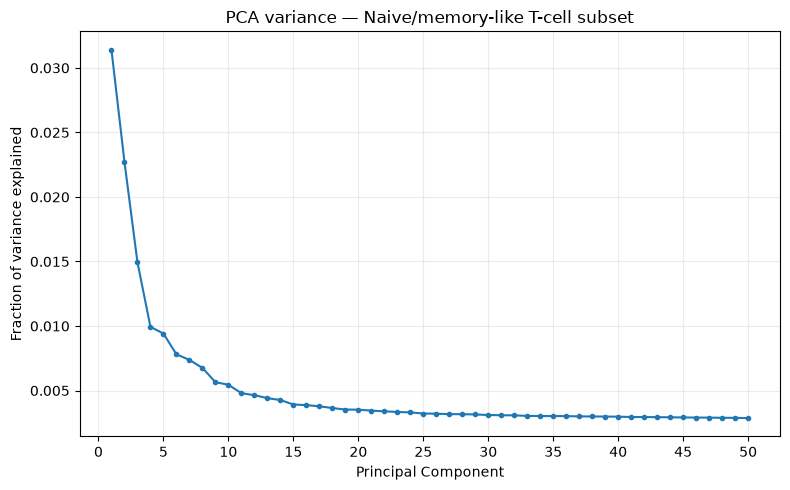

Variance explained by PCs 1–30:

PC01: 0.0314
PC02: 0.0227
PC03: 0.0149
PC04: 0.0099
PC05: 0.0094
PC06: 0.0078
PC07: 0.0074
PC08: 0.0068
PC09: 0.0056
PC10: 0.0054
PC11: 0.0048
PC12: 0.0046
PC13: 0.0044
PC14: 0.0043
PC15: 0.0039
PC16: 0.0039
PC17: 0.0038
PC18: 0.0036
PC19: 0.0035
PC20: 0.0035
PC21: 0.0034
PC22: 0.0034
PC23: 0.0033
PC24: 0.0033
PC25: 0.0032
PC26: 0.0032
PC27: 0.0032
PC28: 0.0032
PC29: 0.0031
PC30: 0.0031


In [6]:
# ============================================================
# STEP 5 — INSPECT PCA VARIANCE / ELBOW PLOT
# ============================================================
#
# WHY?
# PCA produced 50 components, but we do not necessarily want to
# use all 50 when constructing the T-cell neighbor graph.
#
# Each PC captures progressively less variation in the dataset.
#
# We inspect the variance-ratio curve ("elbow plot") to help choose
# a reasonable number of PCs for downstream:
#
#       PCA
#        ↓
#   neighbor graph
#        ↓
#      UMAP
#        ↓
#     Leiden
#
# We will NOT choose the number of PCs based only on cumulative
# variance. We will inspect the shape of the curve together with
# the biological structure later.
# ============================================================

import matplotlib.pyplot as plt

variance_ratio = tcell.uns["pca"]["variance_ratio"]

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(variance_ratio) + 1),
    variance_ratio,
    marker="o",
    markersize=3
)

plt.xlabel("Principal Component")
plt.ylabel("Fraction of variance explained")
plt.title("PCA variance — Naive/memory-like T-cell subset")

plt.xticks(range(0, 51, 5))
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Also print PCs 1–30 numerically
print("Variance explained by PCs 1–30:\n")

for i, value in enumerate(variance_ratio[:30], start=1):
    print(f"PC{i:02d}: {value:.4f}")

In [7]:
# ============================================================
# STEP 6 — BUILD T-CELL-SPECIFIC NEIGHBOR GRAPH
# ============================================================
#
# We have now:
#
#   80,895 broad Naive/memory-like T cells
#            ↓
#   3,000 T-cell-specific HVGs
#            ↓
#   T-cell-specific PCA
#
# We now construct a NEW nearest-neighbor graph using the first
# 20 T-cell-specific principal components.
#
# WHY 20 PCs?
# The PCA elbow plot showed that the largest contributions occur
# in the early PCs, with the variance curve becoming relatively
# flat around PC15–20.
#
# n_neighbors = 15 is a common starting value for identifying
# local transcriptional structure.
#
# IMPORTANT:
# This replaces the old neighbor graph inherited from the complete
# immune-cell analysis. It is now based specifically on variation
# among these T cells.
# ============================================================

sc.pp.neighbors(
    tcell,
    n_neighbors=15,
    n_pcs=20,
    random_state=42
)

print("T-cell-specific neighbor graph completed.")

print("\nConnectivity matrix shape:")
print(tcell.obsp["connectivities"].shape)

print("\nDistance matrix shape:")
print(tcell.obsp["distances"].shape)

print("\nNumber of cells represented:")
print(tcell.n_obs)

T-cell-specific neighbor graph completed.

Connectivity matrix shape:
(80895, 80895)

Distance matrix shape:
(80895, 80895)

Number of cells represented:
80895


T-cell-specific UMAP completed.
UMAP coordinates shape: (80895, 2)


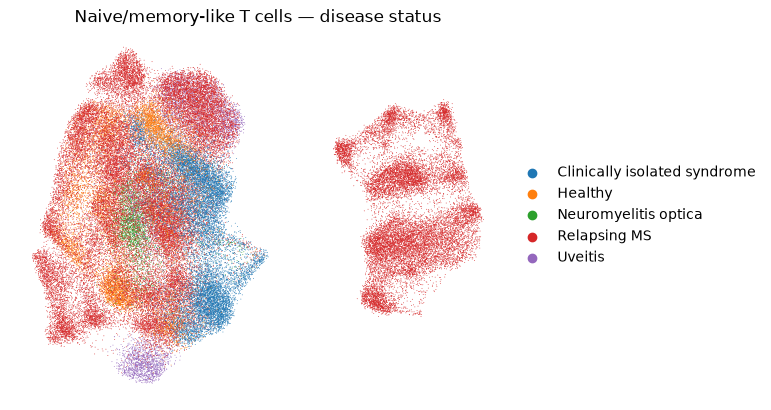

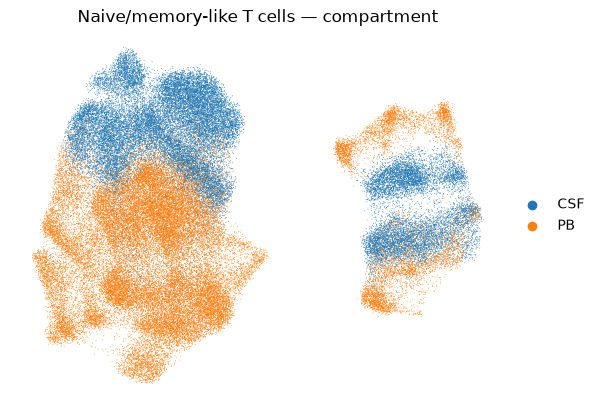

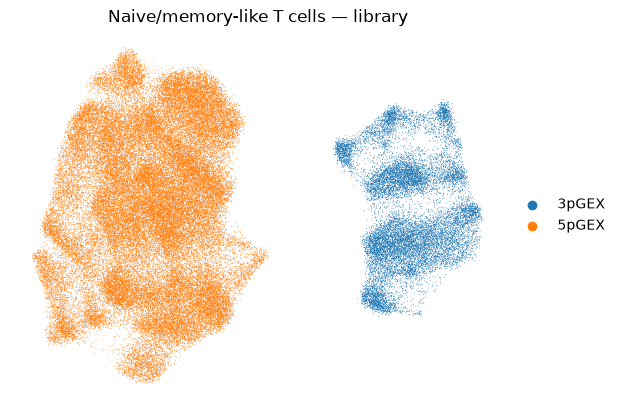

In [8]:
# ============================================================
# STEP 7 — CALCULATE T-CELL-SPECIFIC UMAP
# ============================================================
#
# We have now rebuilt the representation specifically for the
# broad Naive/memory-like T-cell population:
#
#   80,895 T cells
#        ↓
#   3,000 T-cell-specific HVGs
#        ↓
#   T-cell-specific PCA
#        ↓
#   neighbor graph using PCs 1–20
#        ↓
#   UMAP  ← WE ARE HERE
#
# UMAP gives us a 2-dimensional visualization of the transcriptional
# structure within this broad T-cell population.
#
# IMPORTANT:
# UMAP is primarily a visualization. Separate regions on a UMAP do
# not automatically represent biologically distinct T-cell types.
# We will later use clustering + marker genes + donor/sample
# distribution to decide whether the structures are meaningful.
# ============================================================

sc.tl.umap(
    tcell,
    random_state=42
)

print("T-cell-specific UMAP completed.")
print("UMAP coordinates shape:", tcell.obsm["X_umap"].shape)

# First visualize the structure WITHOUT assigning new clusters yet.
sc.pl.umap(
    tcell,
    color="disease_status",
    title="Naive/memory-like T cells — disease status",
    frameon=False
)

sc.pl.umap(
    tcell,
    color="compartment",
    title="Naive/memory-like T cells — compartment",
    frameon=False
)

sc.pl.umap(
    tcell,
    color="library",
    title="Naive/memory-like T cells — library",
    frameon=False
)

In [9]:
# ============================================================
# STEP 8 — RESTRICT TO THE MATCHED CSF + 5pGEX T-CELL DATASET
# ============================================================
#
# The T-cell-specific UMAP revealed a very strong separation
# between 3pGEX and 5pGEX libraries.
#
# This means that clustering all 80,895 cells together could cause
# technical library differences to influence the clusters.
#
# Our original MS-vs-Healthy pseudobulk analysis was performed in:
#
#     Naive/memory-like T cells
#             +
#             CSF
#             +
#            5pGEX
#             +
#       Healthy / Relapsing MS
#
# Therefore, to investigate WHICH T-cell state contributes to our
# previously observed translation/mitochondrial signal, we now
# restrict the subclustering analysis to the same biological and
# technical context.
#
# We first inspect the resulting sample/donor representation.
# ============================================================

tcell_csf_5p = tcell[
    (tcell.obs["compartment"] == "CSF") &
    (tcell.obs["library"] == "5pGEX") &
    (tcell.obs["disease_status"].isin(["Healthy", "Relapsing MS"]))
].copy()

print("Matched CSF + 5pGEX T-cell subset:")
print(tcell_csf_5p)

print("\nTotal number of cells:")
print(tcell_csf_5p.n_obs)

print("\nCells by disease status:")
print(tcell_csf_5p.obs["disease_status"].value_counts())

print("\nNumber of donors by disease status:")
print(
    tcell_csf_5p.obs[
        ["donor", "disease_status"]
    ]
    .drop_duplicates()
    ["disease_status"]
    .value_counts()
)

print("\nCells per donor:")
print(
    tcell_csf_5p.obs
    .groupby(["disease_status", "donor"], observed=True)
    .size()
)

Matched CSF + 5pGEX T-cell subset:
AnnData object with n_obs × n_vars = 17220 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_0_5', 'cell_type'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'highly_variable_whole_dataset'
    uns: 'cell_type_colors', 'compartment_colors', 'dendrogram_leiden_0_5', 'hvg', 'leiden_0_5', 'leiden_0_5_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap', 'disease_status_colors', 'library_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

Total number of cells:
17220

Cells by disease status:
disease_status
Relapsing MS    14073
Healthy          3147
Name: count, dtype: int64

Number of donors by disease stat

In [10]:
# ============================================================
# STEP 9 — RECALCULATE HVGs WITHIN MATCHED CSF + 5p T CELLS
# ============================================================
#
# CURRENT POPULATION:
#
#   Broad Naive/memory-like T cells
#              ↓
#             CSF
#              ↓
#            5pGEX
#              ↓
#     Healthy + Relapsing MS
#
#       17,220 cells
#       13 donors
#       3 Healthy + 10 MS
#
# WHY RECALCULATE HVGs AGAIN?
#
# The previous 3,000 HVGs were identified across all 80,895
# Naive/memory-like T cells, which included:
#
#       - CSF and peripheral blood
#       - 5pGEX and 3pGEX
#       - several disease groups
#
# Now we want genes that distinguish transcriptional states
# specifically WITHIN the population relevant to our original
# MS-vs-Healthy result.
#
# tcell_csf_5p.X is already normalized/log-transformed, so:
#
#       DO NOT normalize again
#       DO NOT log-transform again
#
# We use the Seurat HVG method, as before.
# ============================================================

sc.pp.highly_variable_genes(
    tcell_csf_5p,
    n_top_genes=3000,
    flavor="seurat"
)

print("Number of matched-subset HVGs:")
print(tcell_csf_5p.var["highly_variable"].sum())

print("\nFirst 20 HVGs:")
print(
    tcell_csf_5p.var_names[
        tcell_csf_5p.var["highly_variable"]
    ][:20].tolist()
)

Number of matched-subset HVGs:
3000

First 20 HVGs:
['AL627309.3', 'ISG15', 'AGRN', 'TNFRSF4', 'LINC01786', 'MXRA8', 'ANKRD65', 'TMEM240', 'FO704657.1', 'CALML6', 'PRKCZ-AS1', 'AL513320.1', 'AL805961.2', 'LINC00337', 'LINC01672', 'CAMTA1-DT', 'UTS2', 'AL034417.3', 'ENO1', 'SLC2A7']


In [11]:
# ============================================================
# STEP 10 — PCA WITHIN MATCHED CSF + 5p T CELLS
# ============================================================
#
# We have selected 3,000 genes that are highly variable specifically
# within our matched CSF + 5pGEX T-cell population.
#
# We now use those genes to calculate a NEW PCA.
#
# This PCA is independent of:
#   - peripheral blood cells
#   - 3pGEX cells
#   - other disease groups
#
# Therefore, the major PCs should now describe variation WITHIN
# the exact T-cell population relevant to our MS-vs-Healthy analysis.
#
# We calculate 50 PCs initially. We will inspect their variance
# before deciding how many to use for the neighbor graph.
# ============================================================

sc.tl.pca(
    tcell_csf_5p,
    n_comps=50,
    mask_var="highly_variable",
    svd_solver="arpack"
)

print("Matched-subset PCA completed.")

print("\nPCA matrix shape:")
print(tcell_csf_5p.obsm["X_pca"].shape)

print("\nVariance explained by first 10 PCs:")
print(
    tcell_csf_5p.uns["pca"]["variance_ratio"][:10]
)

print("\nCumulative variance explained by first 10 PCs:")
print(
    tcell_csf_5p.uns["pca"]["variance_ratio"][:10].sum()
)

Matched-subset PCA completed.

PCA matrix shape:
(17220, 50)

Variance explained by first 10 PCs:
[0.01267229 0.01078605 0.01001982 0.00744144 0.00686468 0.00590129
 0.00549963 0.00532288 0.0048712  0.00447575]

Cumulative variance explained by first 10 PCs:
0.073855035


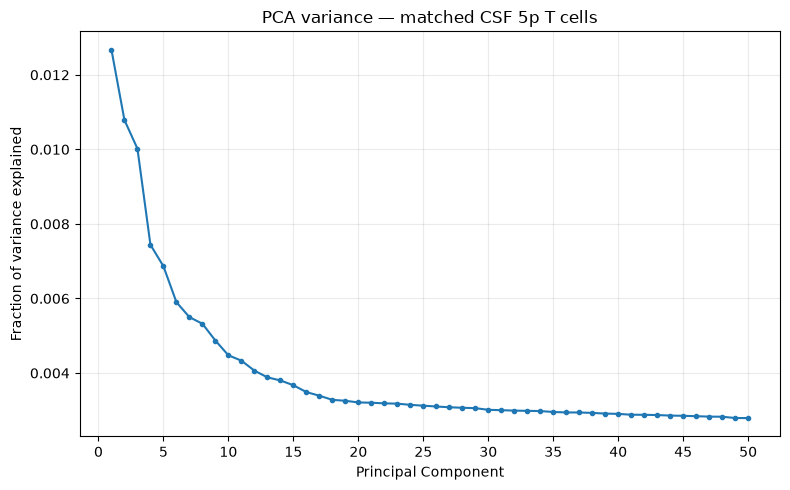

Variance explained by PCs 1–30:

PC01: 0.0127
PC02: 0.0108
PC03: 0.0100
PC04: 0.0074
PC05: 0.0069
PC06: 0.0059
PC07: 0.0055
PC08: 0.0053
PC09: 0.0049
PC10: 0.0045
PC11: 0.0043
PC12: 0.0041
PC13: 0.0039
PC14: 0.0038
PC15: 0.0037
PC16: 0.0035
PC17: 0.0034
PC18: 0.0033
PC19: 0.0033
PC20: 0.0032
PC21: 0.0032
PC22: 0.0032
PC23: 0.0032
PC24: 0.0031
PC25: 0.0031
PC26: 0.0031
PC27: 0.0031
PC28: 0.0031
PC29: 0.0031
PC30: 0.0030


In [12]:
# ============================================================
# STEP 11 — INSPECT PCA VARIANCE IN MATCHED CSF + 5p T CELLS
# ============================================================
#
# The first 10 PCs explain ~7.4% of total variation.
#
# This relatively low percentage is not unexpected because we are
# now examining a much more homogeneous population:
#
#   - same broad T-cell population
#   - same compartment (CSF)
#   - same library chemistry (5pGEX)
#   - only Healthy and Relapsing MS
#
# We therefore inspect how quickly the contribution of successive
# PCs decreases rather than choosing the number of PCs solely from
# cumulative explained variance.
# ============================================================

import matplotlib.pyplot as plt

variance_ratio = tcell_csf_5p.uns["pca"]["variance_ratio"]

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(variance_ratio) + 1),
    variance_ratio,
    marker="o",
    markersize=3
)

plt.xlabel("Principal Component")
plt.ylabel("Fraction of variance explained")
plt.title("PCA variance — matched CSF 5p T cells")

plt.xticks(range(0, 51, 5))
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Variance explained by PCs 1–30:\n")

for i, value in enumerate(variance_ratio[:30], start=1):
    print(f"PC{i:02d}: {value:.4f}")

In [13]:
# ============================================================
# STEP 12 — BUILD NEIGHBOR GRAPH FOR MATCHED CSF + 5p T CELLS
# ============================================================
#
# We now construct the nearest-neighbor graph specifically within
# our 17,220 matched T cells.
#
# Input:
#   17,220 CSF Naive/memory-like T cells
#   5pGEX only
#   Healthy + Relapsing MS only
#   3,000 subset-specific HVGs
#   subset-specific PCA
#
# We use:
#   n_pcs = 20
#       Based on the PCA elbow, which becomes relatively flat
#       around PC15–20.
#
#   n_neighbors = 15
#       A reasonable starting value for capturing local
#       transcriptional structure.
#
# This graph will subsequently be used for:
#
#       neighbor graph
#             ↓
#           UMAP
#             ↓
#          Leiden
#             ↓
#       marker analysis
#             ↓
#     T-cell state annotation
#
# IMPORTANT:
# Clusters are not automatically biological cell types.
# We will require marker-expression evidence AND inspect their
# distribution across donors before assigning biological labels.
# ============================================================

sc.pp.neighbors(
    tcell_csf_5p,
    n_neighbors=15,
    n_pcs=20,
    random_state=42
)

print("Matched T-cell neighbor graph completed.")

print("\nConnectivity matrix:")
print(tcell_csf_5p.obsp["connectivities"].shape)

print("\nDistance matrix:")
print(tcell_csf_5p.obsp["distances"].shape)

Matched T-cell neighbor graph completed.

Connectivity matrix:
(17220, 17220)

Distance matrix:
(17220, 17220)


Matched CSF T-cell UMAP completed.
UMAP shape: (17220, 2)


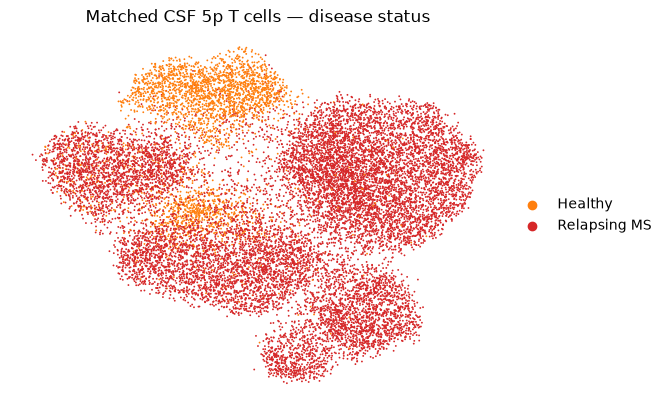

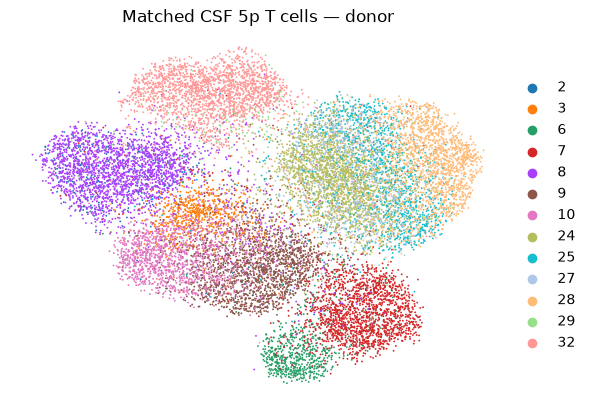

In [14]:
# ============================================================
# STEP 13 — UMAP OF MATCHED CSF + 5p T CELLS
# ============================================================
#
# We now calculate a completely new UMAP using the neighbor graph
# constructed specifically from our matched population:
#
#       17,220 broad Naive/memory-like T cells
#                    ↓
#                  CSF only
#                    ↓
#                 5pGEX only
#                    ↓
#           Healthy + Relapsing MS
#
# Because compartment and library chemistry are now fixed, the
# remaining structure should be much more useful for investigating
# finer T-cell transcriptional states.
#
# HOWEVER:
# We still must NOT interpret UMAP islands as biological subtypes
# until we examine:
#
#       1. Leiden clusters
#       2. marker genes
#       3. donor representation
#
# First we visualize disease status and donor identity.
# ============================================================

sc.tl.umap(
    tcell_csf_5p,
    random_state=42
)

print("Matched CSF T-cell UMAP completed.")
print("UMAP shape:", tcell_csf_5p.obsm["X_umap"].shape)

# Disease-status distribution
sc.pl.umap(
    tcell_csf_5p,
    color="disease_status",
    title="Matched CSF 5p T cells — disease status",
    frameon=False
)

# Donor distribution
sc.pl.umap(
    tcell_csf_5p,
    color="donor",
    title="Matched CSF 5p T cells — donor",
    frameon=False,
    legend_loc="right margin"
)

/tmp/ipykernel_260785/3079226349.py:24: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Number of clusters:
5

Cells per cluster:
tcell_leiden_0_5
0    6016
1    4046
2    2491
3    2490
4    2177
Name: count, dtype: int64


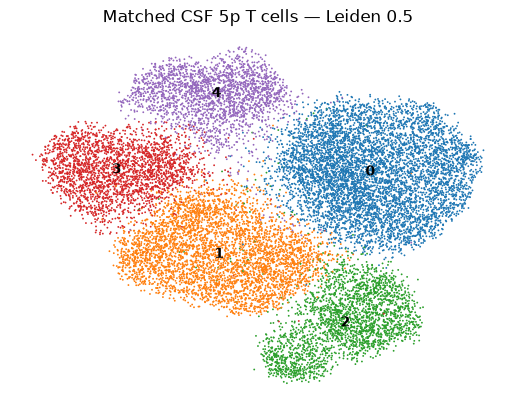

In [15]:
# ============================================================
# STEP 15 — LEIDEN SUBCLUSTERING OF MATCHED CSF T CELLS
# ============================================================
#
# The donor UMAP showed substantial donor-associated structure.
#
# Therefore, we must be especially careful:
#
#     Leiden cluster ≠ automatically a T-cell subtype
#
# A useful biological T-cell state should ideally have:
#
#   1. A coherent marker-gene program
#   2. Representation across multiple donors
#   3. Known/biologically plausible T-cell markers
#
# We start with Leiden resolution = 0.5.
#
# This is an exploratory starting resolution. We can later test
# whether the biological conclusions are stable at nearby
# resolutions.
# ============================================================

sc.tl.leiden(
    tcell_csf_5p,
    resolution=0.5,
    key_added="tcell_leiden_0_5",
    random_state=42
)

print("Number of clusters:")
print(tcell_csf_5p.obs["tcell_leiden_0_5"].nunique())

print("\nCells per cluster:")
print(
    tcell_csf_5p.obs["tcell_leiden_0_5"]
    .value_counts()
    .sort_index()
)

# Visualize clusters
sc.pl.umap(
    tcell_csf_5p,
    color="tcell_leiden_0_5",
    title="Matched CSF 5p T cells — Leiden 0.5",
    frameon=False,
    legend_loc="on data"
)

In [16]:
# ============================================================
# STEP 16 — IDENTIFY MARKER GENES FOR EACH T-CELL CLUSTER
# ============================================================
#
# We obtained 5 exploratory Leiden clusters:
#
#       Cluster 0
#       Cluster 1
#       Cluster 2
#       Cluster 3
#       Cluster 4
#
# Now we ask:
#
#   "Which genes are relatively enriched in each cluster compared
#    with the other cells?"
#
# This helps us determine whether the clusters correspond to
# recognizable T-cell states.
#
# IMPORTANT:
#
# This marker analysis is for CELL-STATE ANNOTATION.
#
# It is NOT being used to claim MS-vs-Healthy differential
# expression. For disease comparisons, donor remains the
# biological replicate and we will use pseudobulk.
#
# We use the Wilcoxon test because it is commonly used for
# exploratory single-cell cluster-marker identification.
# ============================================================

sc.tl.rank_genes_groups(
    tcell_csf_5p,
    groupby="tcell_leiden_0_5",
    method="wilcoxon",
    key_added="tcell_cluster_markers"
)

# Display the top 15 marker genes for every cluster
marker_df = sc.get.rank_genes_groups_df(
    tcell_csf_5p,
    group=None,
    key="tcell_cluster_markers"
)

top15_markers = (
    marker_df
    .groupby("group", observed=True)
    .head(15)
)

for cluster in sorted(
    top15_markers["group"].astype(str).unique(),
    key=int
):
    genes = top15_markers.loc[
        top15_markers["group"].astype(str) == cluster,
        "names"
    ].tolist()

    print(f"\nCLUSTER {cluster}")
    print(", ".join(genes))


CLUSTER 0
MTRNR2L12, MALAT1, KLF2, TMSB4X, RPS4X, RPS2, B2M, ACTB, RPS29, RPS27, RPS8, RPS6, RPL39, EEF1A1, PNRC1

CLUSTER 1
EEF1G, RPL17, MT-ATP8, RPS26, PTPRCAP, MT-ND6, RNASEK, ARPC1B, CRIP1, RPS17, RBMX, MT-ND5, MT-CYB, XIST, PCBP1

CLUSTER 2
RPS4Y1, MT-ND2, MZT2B, SRRM2, YPEL3, MT-ND1, URI1, PTP4A2, RPL23, NEAT1, CD48, NKTR, ANKRD11, ERN1, TNRC6B

CLUSTER 3
RPS4Y1, RPS10, RPL19, RPL7A, RPLP0, RPL41, RPL5, RPS7, RPL36, FAU, RPS18, RPL11, RPL12, RPL30, RPL26

CLUSTER 4
RPS4Y1, RPS26, MTRNR2L12, RPL36AL, PPDPF, SNRPD2, SNHG8, TBC1D10C, PAXX, FLNA, SMDT1, EEF1D, PPIB, S100A6, SPSB3


In [19]:
# ============================================================
# STEP 17 — CHECK DONOR REPRESENTATION WITHIN EACH CLUSTER
# ============================================================
#
# GOAL:
# Determine whether our 5 Leiden clusters are shared across
# multiple donors or mainly driven by individual donors.
#
# This is essential because the donor UMAP showed strong
# donor-associated structure.
#
# Remember:
#       Cells = observations
#       Donors = biological replicates
#
# A Leiden cluster dominated by one donor should not automatically
# be interpreted as a distinct biological T-cell subtype.
# ============================================================

# Use the original donor column directly.
# Convert to string so donor IDs are treated as labels/categories.
donor_labels = tcell_csf_5p.obs["donor"].astype(str)

cluster_labels = tcell_csf_5p.obs["tcell_leiden_0_5"].astype(str)

# ------------------------------------------------------------
# 1. Number of cells from each donor in each cluster
# ------------------------------------------------------------

donor_cluster_counts = pd.crosstab(
    donor_labels,
    cluster_labels
)

print("CELL COUNTS — DONOR × CLUSTER")
print(donor_cluster_counts)


# ------------------------------------------------------------
# 2. For each donor:
#    What percentage of that donor's cells belongs to each cluster?
# ------------------------------------------------------------

donor_cluster_percent = (
    donor_cluster_counts
    .div(donor_cluster_counts.sum(axis=1), axis=0)
    * 100
)

print("\nPERCENTAGE OF EACH DONOR'S CELLS IN EACH CLUSTER")
print(donor_cluster_percent.round(1))


# ------------------------------------------------------------
# 3. How many donors contribute meaningfully to each cluster?
#
# We use >=20 cells as a simple descriptive threshold.
# This is NOT a statistical significance threshold.
# ------------------------------------------------------------

donors_per_cluster = (
    donor_cluster_counts >= 20
).sum(axis=0)

print("\nNUMBER OF DONORS CONTRIBUTING >=20 CELLS TO EACH CLUSTER")
print(donors_per_cluster)


# ------------------------------------------------------------
# 4. Is any cluster dominated by a single donor?
#
# For each cluster, calculate what percentage comes from its
# largest contributing donor.
# ------------------------------------------------------------

cluster_donor_percent = (
    donor_cluster_counts
    .div(donor_cluster_counts.sum(axis=0), axis=1)
    * 100
)

largest_donor_contribution = cluster_donor_percent.max(axis=0)

print("\nLARGEST SINGLE-DONOR CONTRIBUTION TO EACH CLUSTER (%)")
print(largest_donor_contribution.round(1))


# ------------------------------------------------------------
# 5. Identify which donor is the largest contributor
# ------------------------------------------------------------

largest_donor = cluster_donor_percent.idxmax(axis=0)

print("\nLARGEST CONTRIBUTING DONOR FOR EACH CLUSTER")
print(largest_donor)

CELL COUNTS — DONOR × CLUSTER
tcell_leiden_0_5     0     1     2     3     4
donor                                         
10                   4  1280     0    15     2
2                    0    24     6   286     1
24                2357    44     7     1    26
25                1173    23    14     6     8
27                 654    41     9     0     6
28                1619     8     4     2     8
29                  63     2     5    14    94
3                   16   763     2    38     6
32                  32     5     5    32  1931
6                   11     7   659    11     0
7                   33    39  1704    32     7
8                   11   151    35  2043    84
9                   43  1659    41    10     4

PERCENTAGE OF EACH DONOR'S CELLS IN EACH CLUSTER
tcell_leiden_0_5     0     1     2     3     4
donor                                         
10                 0.3  98.4   0.0   1.2   0.2
2                  0.0   7.6   1.9  90.2   0.3
24                96.8   1.

Available markers:
['CD3D', 'CD3E', 'TRAC', 'CCR7', 'SELL', 'TCF7', 'LEF1', 'MAL', 'IL7R', 'CD4', 'CD8A', 'CD8B', 'FOXP3', 'IL2RA', 'CTLA4', 'TIGIT', 'IKZF2', 'NKG7', 'GNLY', 'GZMB', 'GZMK', 'PRF1', 'TNFRSF4', 'TNFRSF9', 'HLA-DRA']

Missing markers:
[]


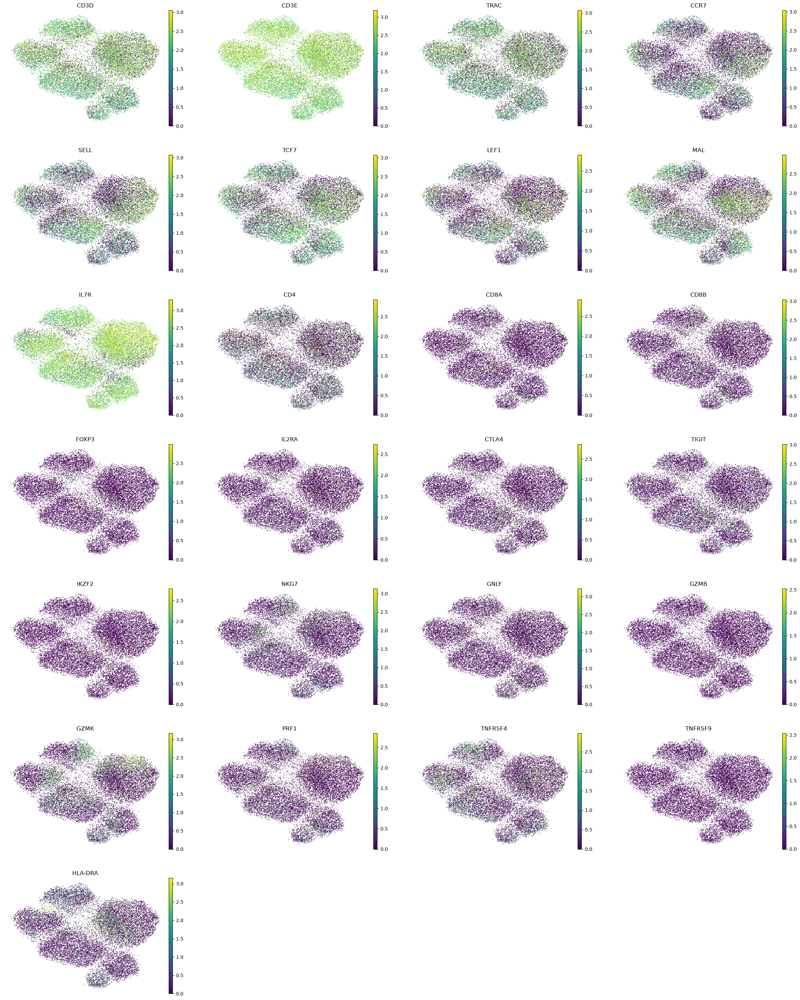

In [20]:
# ============================================================
# STEP 18 — INSPECT CANONICAL T-CELL STATE MARKERS
# ============================================================
#
# Leiden clustering was strongly associated with donor identity.
# Therefore, we will NOT interpret those clusters as biological
# T-cell subtypes.
#
# Instead, we now inspect established marker genes representing
# major T-cell identities/states.
#
# These markers are used as a diagnostic panel, not as automatic
# labels. A biological annotation should be supported by a
# combination of markers rather than one gene alone.
# ============================================================

marker_panel = [

    # General T-cell markers
    "CD3D", "CD3E", "TRAC",

    # Naive / central-memory-like program
    "CCR7", "SELL", "TCF7", "LEF1", "MAL", "IL7R",

    # CD4-related
    "CD4",

    # CD8-related
    "CD8A", "CD8B",

    # Regulatory T-cell-associated
    "FOXP3", "IL2RA", "CTLA4", "TIGIT", "IKZF2",

    # Cytotoxic / effector program
    "NKG7", "GNLY", "GZMB", "GZMK", "PRF1",

    # Activation-associated
    "TNFRSF4", "TNFRSF9", "HLA-DRA"
]

# Keep only genes actually present in the dataset
available_markers = [
    gene for gene in marker_panel
    if gene in tcell_csf_5p.var_names
]

missing_markers = [
    gene for gene in marker_panel
    if gene not in tcell_csf_5p.var_names
]

print("Available markers:")
print(available_markers)

print("\nMissing markers:")
print(missing_markers)

# Visualize expression on the matched UMAP
sc.pl.umap(
    tcell_csf_5p,
    color=available_markers,
    ncols=4,
    frameon=False,
    cmap="viridis"
)


naive_memory_score
Genes used: ['CCR7', 'SELL', 'TCF7', 'LEF1', 'MAL', 'IL7R']

regulatory_like_score
Genes used: ['FOXP3', 'IL2RA', 'CTLA4', 'TIGIT', 'IKZF2']

cytotoxic_score
Genes used: ['NKG7', 'GNLY', 'GZMB', 'GZMK', 'PRF1']

activation_score
Genes used: ['TNFRSF4', 'TNFRSF9', 'HLA-DRA']

State scores successfully calculated.


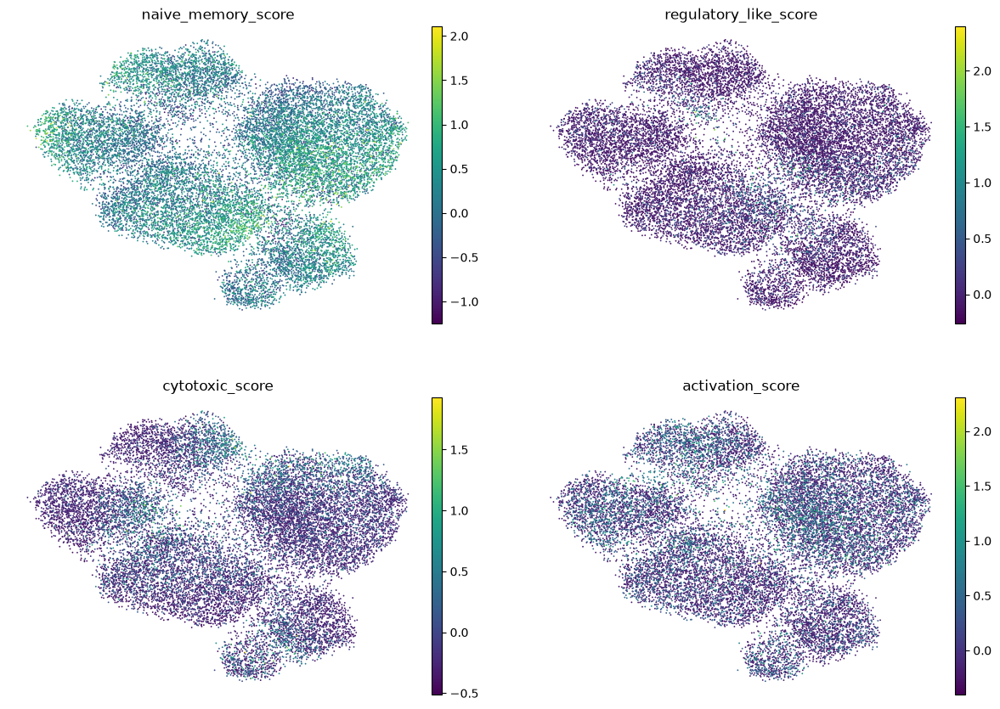

In [21]:
# ============================================================
# STEP 19 — CALCULATE T-CELL STATE PROGRAM SCORES
# ============================================================
#
# WHY CHANGE FROM CLUSTERS TO SCORES?
#
# Our Leiden clusters were strongly associated with individual
# donors, and canonical markers did not reveal five clean,
# discrete T-cell subtypes.
#
# Instead, the cells appear to contain overlapping/continuous
# transcriptional programs.
#
# Therefore, rather than forcing every cell into labels such as
# "Treg" or "memory", we calculate continuous gene-program scores.
#
# A higher score means that, RELATIVE to matched background genes,
# the cell shows stronger expression of that gene program.
#
# IMPORTANT:
# These scores are exploratory descriptions of transcriptional
# state. They do NOT directly measure T-cell function.
# ============================================================

state_programs = {

    # Naive / central-memory-like transcriptional program
    "naive_memory_score": [
        "CCR7", "SELL", "TCF7", "LEF1", "MAL", "IL7R"
    ],

    # Regulatory-associated program
    # We call this "regulatory-like", NOT definitive Treg identity.
    "regulatory_like_score": [
        "FOXP3", "IL2RA", "CTLA4", "TIGIT", "IKZF2"
    ],

    # Cytotoxic / effector-associated program
    "cytotoxic_score": [
        "NKG7", "GNLY", "GZMB", "GZMK", "PRF1"
    ],

    # Activation-associated program
    "activation_score": [
        "TNFRSF4", "TNFRSF9", "HLA-DRA"
    ]
}

# Keep only genes actually present in the dataset
for score_name, genes in state_programs.items():

    genes_present = [
        gene for gene in genes
        if gene in tcell_csf_5p.var_names
    ]

    print(f"\n{score_name}")
    print("Genes used:", genes_present)

    sc.tl.score_genes(
        tcell_csf_5p,
        gene_list=genes_present,
        score_name=score_name,
        random_state=42
    )

print("\nState scores successfully calculated.")

# Visualize the four continuous programs
sc.pl.umap(
    tcell_csf_5p,
    color=[
        "naive_memory_score",
        "regulatory_like_score",
        "cytotoxic_score",
        "activation_score"
    ],
    ncols=2,
    frameon=False,
    cmap="viridis"
)

Translation genes available:
['RPL3', 'RPL4', 'RPL5', 'RPL6', 'RPL7', 'RPL8', 'RPL9', 'RPL10', 'RPL11', 'RPL12', 'RPS3', 'RPS4X', 'RPS5', 'RPS6', 'RPS7', 'RPS8', 'RPS9', 'RPS10', 'RPS11', 'RPS12']

Mitochondrial translation genes available:
['MRPL3', 'MRPL9', 'MRPL11', 'MRPL12', 'MRPL13', 'MRPL14', 'MRPL15', 'MRPL17', 'MRPL18', 'MRPS5', 'MRPS7', 'MRPS9', 'MRPS11', 'MRPS12', 'MRPS14', 'MRPS15', 'MRPS16', 'MRPS17', 'MRPS18A']


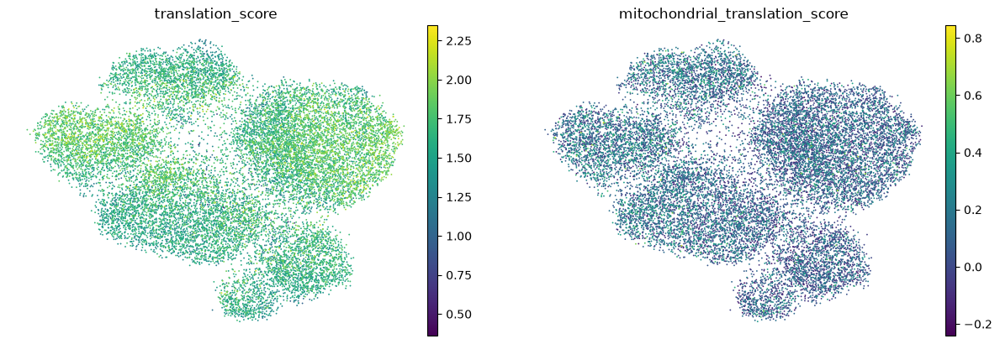

In [22]:
# ============================================================
# STEP 20 — SCORE TRANSLATION AND MITOCHONDRIAL PROGRAMS
# ============================================================
#
# Our donor-level GSEA identified the strongest MS-associated
# differences in two broad biological themes:
#
#   1. Protein translation / ribosomal machinery
#   2. Mitochondrial translation / energy-related machinery
#
# We now calculate exploratory single-cell scores for representative
# genes from these programs.
#
# PURPOSE:
# Determine WHERE these programs are expressed across the T-cell
# transcriptional landscape and whether they appear associated
# with particular T-cell states.
#
# IMPORTANT:
# These single-cell scores do NOT replace our donor-level GSEA.
# They are only being used to localize/visualize the programs.
#
# Disease-associated statistical testing must still be performed
# at the DONOR level.
# ============================================================


# Representative cytosolic translation / ribosomal genes
translation_genes = [
    "RPL3", "RPL4", "RPL5", "RPL6", "RPL7", "RPL8",
    "RPL9", "RPL10", "RPL11", "RPL12",
    "RPS3", "RPS4X", "RPS5", "RPS6", "RPS7",
    "RPS8", "RPS9", "RPS10", "RPS11", "RPS12"
]


# Representative mitochondrial translation genes
mitochondrial_translation_genes = [
    "MRPL3", "MRPL9", "MRPL11", "MRPL12", "MRPL13",
    "MRPL14", "MRPL15", "MRPL17", "MRPL18",
    "MRPS5", "MRPS7", "MRPS9", "MRPS11", "MRPS12",
    "MRPS14", "MRPS15", "MRPS16", "MRPS17", "MRPS18A"
]


# Keep only genes present in our dataset
translation_present = [
    gene for gene in translation_genes
    if gene in tcell_csf_5p.var_names
]

mito_translation_present = [
    gene for gene in mitochondrial_translation_genes
    if gene in tcell_csf_5p.var_names
]


print("Translation genes available:")
print(translation_present)

print("\nMitochondrial translation genes available:")
print(mito_translation_present)


# Calculate scores
sc.tl.score_genes(
    tcell_csf_5p,
    gene_list=translation_present,
    score_name="translation_score",
    random_state=42
)

sc.tl.score_genes(
    tcell_csf_5p,
    gene_list=mito_translation_present,
    score_name="mitochondrial_translation_score",
    random_state=42
)


# Visualize both programs
sc.pl.umap(
    tcell_csf_5p,
    color=[
        "translation_score",
        "mitochondrial_translation_score"
    ],
    ncols=2,
    frameon=False,
    cmap="viridis"
)

In [23]:
# ============================================================
# STEP 21 — SUMMARIZE PROGRAM SCORES AT THE DONOR LEVEL
# ============================================================
#
# WHY?
#
# We have visualized translation and mitochondrial-translation
# programs at single-cell resolution.
#
# But we must NOT statistically compare:
#
#       14,073 MS cells
#             vs
#        3,147 Healthy cells
#
# because cells from the same donor are not independent biological
# replicates.
#
# Instead, we summarize each transcriptional score for each DONOR.
#
# This gives us:
#
#       10 MS donor observations
#        3 Healthy donor observations
#
# We will first inspect these descriptively.
#
# NOTE:
# This score analysis is a follow-up/localization analysis.
# Our donor-level pseudobulk DESeq2 + GSEA remains the primary
# statistical evidence for the translation/mitochondrial finding.
# ============================================================

score_columns = [
    "translation_score",
    "mitochondrial_translation_score",
    "naive_memory_score",
    "regulatory_like_score",
    "cytotoxic_score",
    "activation_score"
]

# Calculate mean score per donor
donor_scores = (
    tcell_csf_5p.obs
    .groupby(
        ["donor", "disease_status"],
        observed=True
    )[score_columns]
    .mean()
    .reset_index()
)

print("DONOR-LEVEL PROGRAM SCORES")
print(donor_scores.to_string(index=False))


# ------------------------------------------------------------
# Disease-group descriptive summary
# ------------------------------------------------------------

group_summary = (
    donor_scores
    .groupby("disease_status", observed=True)[score_columns]
    .agg(["mean", "median", "std"])
)

print("\nDISEASE-GROUP SUMMARY")
print(group_summary)

DONOR-LEVEL PROGRAM SCORES
donor disease_status  translation_score  mitochondrial_translation_score  naive_memory_score  regulatory_like_score  cytotoxic_score  activation_score
    2        Healthy           1.738949                         0.121426            0.222077              -0.032680        -0.088378          0.046040
    3        Healthy           1.708799                         0.107195            0.106718              -0.020903        -0.056880          0.152361
    6   Relapsing MS           1.530906                         0.060724           -0.005571              -0.003791        -0.094650          0.119108
    7   Relapsing MS           1.570795                         0.051105            0.171256              -0.013260        -0.125273         -0.025790
    8   Relapsing MS           1.703551                         0.128329            0.135265              -0.017394        -0.112960          0.111021
    9   Relapsing MS           1.574380                         0.0

DONOR-LEVEL SPEARMAN CORRELATIONS
                                 naive_memory_score  regulatory_like_score  \
translation_score                             0.192                 -0.110   
mitochondrial_translation_score              -0.275                 -0.115   

                                 cytotoxic_score  activation_score  
translation_score                          0.599             0.209  
mitochondrial_translation_score            0.066             0.137  


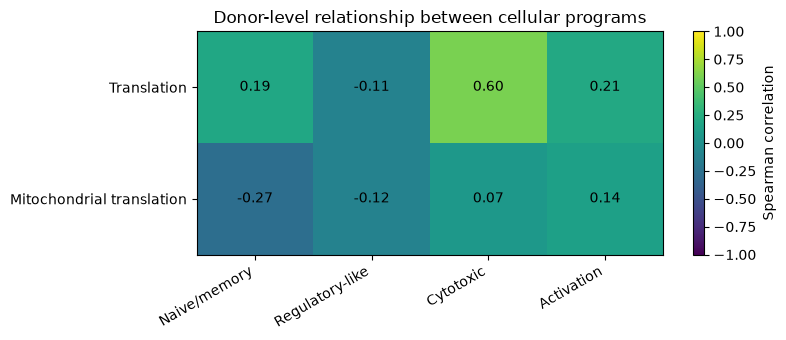

In [24]:
# ============================================================
# STEP 22 — RELATIONSHIP BETWEEN THE MS-ASSOCIATED PROGRAMS
#           AND T-CELL STATE PROGRAMS AT DONOR LEVEL
# ============================================================
#
# QUESTION:
#
# Is the translation / mitochondrial-translation signal simply
# associated with one recognizable T-cell transcriptional state?
#
# For example:
#
#   higher mitochondrial translation
#              ↓
#   higher naive/memory score?
#
# or:
#
#   higher mitochondrial translation
#              ↓
#   higher activation / cytotoxic / regulatory-like score?
#
# IMPORTANT:
#
# We perform this descriptively at DONOR level rather than treating
# thousands of cells as independent observations.
#
# There are only 13 donors, including only 3 Healthy donors.
# Therefore these correlations are exploratory and should not be
# interpreted as strong statistical evidence.
# ============================================================

state_scores = [
    "naive_memory_score",
    "regulatory_like_score",
    "cytotoxic_score",
    "activation_score"
]

program_scores = [
    "translation_score",
    "mitochondrial_translation_score"
]

# Calculate donor-level Spearman correlations
correlation_table = donor_scores[
    program_scores + state_scores
].corr(method="spearman")

# Keep only the relationships we care about
relationship_table = correlation_table.loc[
    program_scores,
    state_scores
]

print("DONOR-LEVEL SPEARMAN CORRELATIONS")
print(relationship_table.round(3))


# ------------------------------------------------------------
# Visualize the correlation matrix
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))

im = ax.imshow(
    relationship_table.values,
    aspect="auto",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(state_scores)))
ax.set_xticklabels(
    [
        "Naive/memory",
        "Regulatory-like",
        "Cytotoxic",
        "Activation"
    ],
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(program_scores)))
ax.set_yticklabels(
    [
        "Translation",
        "Mitochondrial translation"
    ]
)

# Add correlation values to each box
for i in range(len(program_scores)):
    for j in range(len(state_scores)):
        ax.text(
            j,
            i,
            f"{relationship_table.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, ax=ax, label="Spearman correlation")
plt.title("Donor-level relationship between cellular programs")
plt.tight_layout()
plt.show()